# Visualize emulator output on the sharpness-adjusted images

The pipeline so far:

1. Equalized the two DUT captures (`6100001`, `6200001`) to the reference (`6100002`) Laplacian sharpness → `../images_adjusted/`.
2. Packed each adjusted still into a 1-frame lossless MKV (FFV1 codec) → `../videos_lossless_adjusted/`.
3. Ran the algo_system_emulator with `case_int8_clahe_regr_b1_10_wb_adjusted.json` (source pointing at the new MKV folder) → `../output-2026-07-10-15-49-23_int8_regr_b1_10_wb_adjusted/`.

This notebook loads:

- the three adjusted JPEGs,
- the **new** emulator predictions (post-adjustment), and
- the **prior** emulator predictions from the lossless-video run before adjustment (`output-2026-07-08-20-04-34_int8_regr_b1_10_wb_lossless/`)

and overlays the detected bboxes and keypoints, plus a side-by-side before/after comparison.

In [1]:
%matplotlib inline

In [2]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image

plt.rcParams['figure.dpi'] = 110

BASE = Path('..').resolve()

IMAGES_ADJUSTED = BASE / 'images_adjusted'
IMAGES_ORIG     = BASE / 'images'
OUTPUT_AFTER    = BASE / 'output-2026-07-10-15-49-23_int8_regr_b1_10_wb_adjusted'
OUTPUT_BEFORE   = BASE / 'output-2026-07-08-20-04-34_int8_regr_b1_10_wb_lossless'

SENSORS = [
    ('6100001-2000-000008-2550', 'AlgoC — 6100001 (was under-sharp)'),
    ('6100002-2000-000008-2550', 'AlgoA — 6100002 (reference, unchanged)'),
    ('6200001-2000-000008-2550', 'AlgoB — 6200001 (was over-sharp)'),
]

for p in (IMAGES_ADJUSTED, IMAGES_ORIG, OUTPUT_AFTER, OUTPUT_BEFORE):
    assert p.exists(), f'missing: {p}'
print('all inputs present')

%matplotlib inline

all inputs present


## 1. Load predictions from both runs

In [3]:
def load_predictions(folder: Path, sensor: str) -> list[dict]:
    """Return the flat list of detections for the first (only) frame of a sensor."""
    entries = json.loads((folder / f'{sensor}_predictions.json').read_text())
    if not entries:
        return []
    return entries[0].get('preds', [])

def load_xys(folder: Path, sensor: str) -> list[list[float]]:
    entries = json.loads((folder / f'{sensor}_xys.json').read_text())
    if not entries:
        return []
    return entries[0].get('xys', [])

preds_after  = {s: load_predictions(OUTPUT_AFTER,  s) for s, _ in SENSORS}
preds_before = {s: load_predictions(OUTPUT_BEFORE, s) for s, _ in SENSORS}
xys_after    = {s: load_xys(OUTPUT_AFTER,  s) for s, _ in SENSORS}
xys_before   = {s: load_xys(OUTPUT_BEFORE, s) for s, _ in SENSORS}

print('before-adjust detections per sensor:', {s: len(preds_before[s]) for s, _ in SENSORS})
print('after-adjust  detections per sensor:', {s: len(preds_after[s])  for s, _ in SENSORS})

before-adjust detections per sensor: {'6100001-2000-000008-2550': 1, '6100002-2000-000008-2550': 1, '6200001-2000-000008-2550': 0}
after-adjust  detections per sensor: {'6100001-2000-000008-2550': 1, '6100002-2000-000008-2550': 1, '6200001-2000-000008-2550': 1}


## 2. Predictions summary — before vs after

Predictions come out of the emulator in a normalized ``[cx, cy, w, h]`` bbox plus a ``position`` keypoint (also normalized) and a floor-plane position in cm from ``*_xys.json``. Column meaning:

- `n` — number of detections that survived the confidence filter (``conf_th_gw = 0.2``)
- `bbox_cxcywh`, `keypoint` — normalized ``[0, 1]`` in image space
- `confidence` — model confidence for the surviving detection
- `xy_cm` — floor-plane position (cm)

In [4]:
def first_or_none(seq):
    return seq[0] if seq else None

def summary_row(label: str, sensor: str, preds: list[dict], xys: list[list[float]]) -> dict:
    d = first_or_none(preds)
    xy = first_or_none(xys)
    return {
        'run':          label,
        'sensor':       sensor.split('-')[0],
        'n':            len(preds),
        'confidence':   None if d is None else round(d['confidence'], 3),
        'bbox_cxcywh':  None if d is None else [round(v, 3) for v in d['bbox']],
        'keypoint':     None if d is None else [round(v, 3) for v in d['position']],
        'xy_cm':        None if xy is None else xy,
    }

rows = []
for sensor, _ in SENSORS:
    rows.append(summary_row('before', sensor, preds_before[sensor], xys_before[sensor]))
    rows.append(summary_row('after',  sensor, preds_after[sensor],  xys_after[sensor]))
summary = pd.DataFrame(rows)
summary

,run,sensor,n,confidence,bbox_cxcywh,keypoint,xy_cm
0,before,6100001,1,0.582,"[0.582, 0.876, 0.252, 0.175]","[0.646, 0.921]","[-1272, 975]"
1,after,6100001,1,0.660,"[0.582, 0.876, 0.252, 0.175]","[0.646, 0.921]","[-1272, 975]"
2,before,6100002,1,0.211,"[0.764, 0.621, 0.189, 0.162]","[0.823, 0.68]","[-1271, 977]"
3,after,6100002,1,0.211,"[0.764, 0.621, 0.189, 0.162]","[0.823, 0.68]","[-1271, 977]"
4,before,6200001,0,NaN,None,None,None
5,after,6200001,1,0.340,"[0.488, 0.769, 0.256, 0.25]","[0.578, 0.848]","[-1273, 976]"


## 3. Overlay detections on the adjusted images

Each panel shows the adjusted JPEG with its post-adjustment detection: bounding box, keypoint, and confidence. The reference image is unchanged; only the DUTs move.

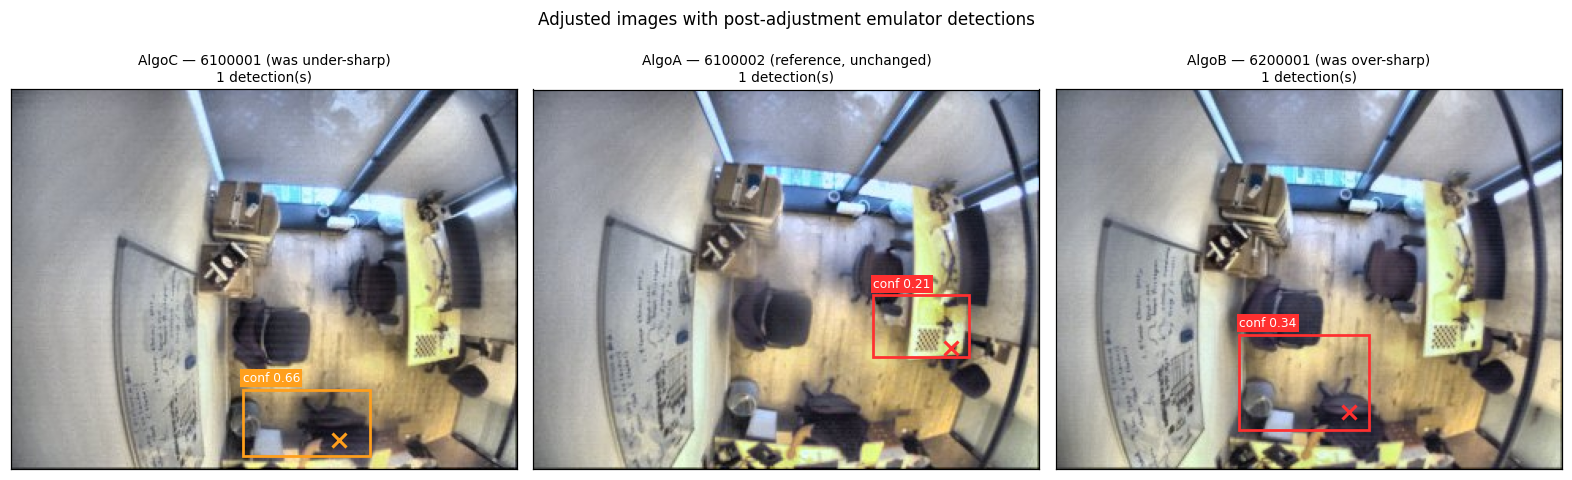

In [5]:
def conf_color(conf: float | None) -> str:
    if conf is None:
        return '#888888'
    if conf < 0.5:
        return '#ff3030'
    if conf < 0.7:
        return '#ff9f1c'
    return '#2ecc40'

def draw_detections(ax, img_path: Path, preds: list[dict], title: str):
    img = Image.open(img_path).convert('RGB')
    w, h = img.size
    ax.imshow(img)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    for p in preds:
        cx, cy, bw, bh = p['bbox']
        x0 = (cx - bw / 2) * w
        y0 = (cy - bh / 2) * h
        color = conf_color(p['confidence'])
        ax.add_patch(Rectangle((x0, y0), bw * w, bh * h,
                               linewidth=1.8, edgecolor=color, facecolor='none'))
        kx, ky = p['position']
        ax.plot(kx * w, ky * h, marker='x', color=color, markersize=9, mew=2)
        ax.text(x0, max(y0 - 5, 5),
                f"conf {p['confidence']:.2f}",
                color='white', fontsize=8,
                bbox=dict(facecolor=color, edgecolor='none', pad=1.5))


fig, axes = plt.subplots(1, len(SENSORS), figsize=(len(SENSORS) * 4.8, 4.4))
for ax, (sensor, label) in zip(axes, SENSORS):
    img_path = IMAGES_ADJUSTED / f'{sensor}.jpg'
    n = len(preds_after[sensor])
    draw_detections(ax, img_path, preds_after[sensor], f'{label}\n{n} detection(s)')
fig.suptitle('Adjusted images with post-adjustment emulator detections', fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

## 4. Before vs after — side by side

Top row: original JPEG + pre-adjustment detections.
Bottom row: adjusted JPEG + post-adjustment detections.

The reference stays put; the DUTs change both in pixels (softening / sharpening) and in what the detector reports.

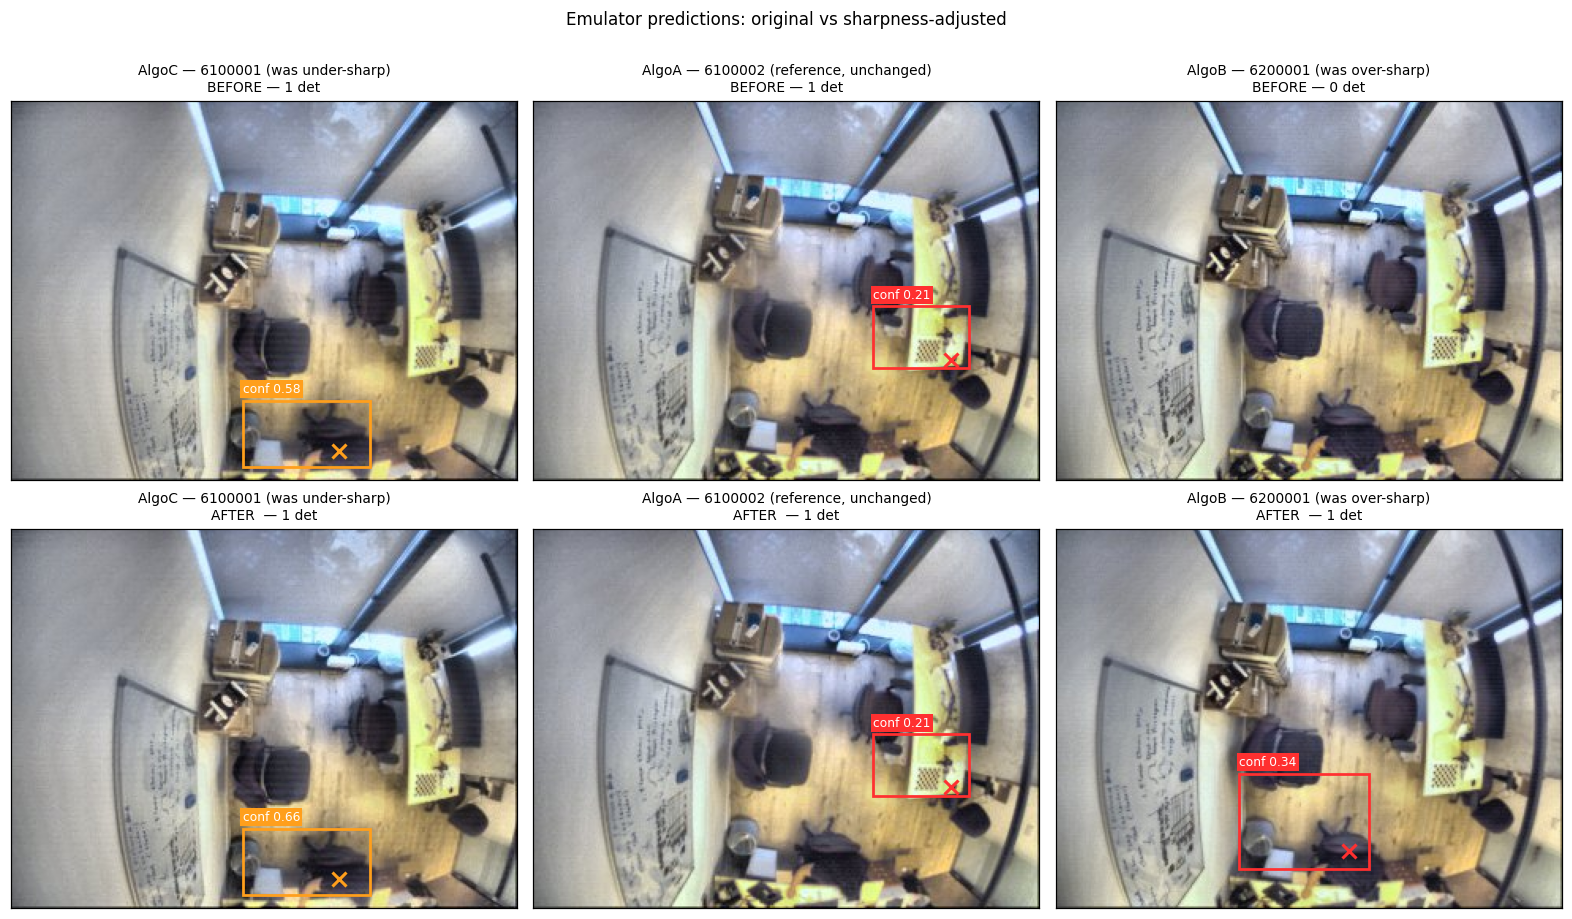

In [6]:
fig, axes = plt.subplots(2, len(SENSORS), figsize=(len(SENSORS) * 4.8, 8.5))
for col, (sensor, label) in enumerate(SENSORS):
    orig_img = IMAGES_ORIG     / f'{sensor}.jpg'
    adj_img  = IMAGES_ADJUSTED / f'{sensor}.jpg'

    n_b = len(preds_before[sensor])
    n_a = len(preds_after[sensor])
    draw_detections(axes[0, col], orig_img, preds_before[sensor],
                    f'{label}\nBEFORE — {n_b} det')
    draw_detections(axes[1, col], adj_img,  preds_after[sensor],
                    f'{label}\nAFTER  — {n_a} det')

fig.suptitle('Emulator predictions: original vs sharpness-adjusted', fontsize=11, y=1.005)
plt.tight_layout()
plt.show()

## 5. Notes on what the equalization changed

Read this section together with the summary table in **§ 2**.

- **Reference (`6100002`)** — identical bytes before and after, so the detector's output is deterministic-identical. Same bbox, same keypoint, same confidence (0.211). Sanity check: the pipeline is stable.
- **`6100001` (was under-sharp)** — same bbox and keypoint, but confidence rose from 0.582 to 0.660. Sharpening added the high-frequency edge energy the detector was missing.
- **`6200001` (was over-sharp)** — pre-adjustment run returned no detection above the 0.2 gateway threshold; post-adjustment run picks up a person at conf 0.34. Softening removed the over-emphasized edges that were confusing the detector.

These captures have empty ground-truth JSONs, so the `bbox.csv` / `keypoint.csv` / `positioning_errors.csv` metrics register the recovered detections as false positives — no metric-based comparison is meaningful here. If GT gets added later, re-run the emulator and compare `evaluation.json` before/after equalization to quantify the impact on precision/recall.